# Tarea 2 · Parte 1 — Corpus y extracción (OCR + ASR)

**Pregunta guía:** ¿Pueden convertirse documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

| | |
|---|---|
| **Fecha de extracción** | 27 de octubre de 2026 |
| **OCR** | PaddleOCR 3.0.3 sobre PaddlePaddle 3.0.0 · PP-OCRv5 *mobile* (detección + reconocimiento), CPU |
| **ASR** | faster-whisper 1.2.1 · Whisper large-v3-turbo (CTranslate2 int8, CPU) + VAD Silero |
| **Diarización** | huellas de voz WeSpeaker ResNet34 (pyannote.audio 4.0.7) + clustering jerárquico (`voz.diarizar`) |
| **Seudonimización** | NER `mrm8488/bert-spanish-cased-finetuned-ner` + revisión humana + `voz.seudonimizar` (difuso, rapidfuzz) |

### Fuentes y licencias

| Corpus | Tipo | Cantidad | Fuente | Licencia / uso |
|---|---|---|---|---|
| Documentos | impreso | 8 | Captura propia del PDF del *Catálogo de periódicos cusqueños del siglo XIX* (Glave, 1999; UNSAAC, Archivo Departamental del Cusco, CBC), págs. 2-9 | © Derechos reservados: se publica solo el texto con fines académicos, no la imagen |
| Documentos | manuscrito | 9 | Captura propia de una copia literal de partida registral (SUNARP, Oficina Registral de Cusco), asientos manuscritos de 1911 a 1995 | Publicidad registral con datos personales: texto seudonimizado, imagen no publicada |
| Documentos | foto | 8 | Fotos propias con celular, con sombra o inclinación, de ejemplares del *Registro Oficial del Departamento* (Cusco, 1857-1862) | Impreso en dominio público; fotos propias CC BY 4.0 |
| Audio | entrevistas y testimonios | 15 clips | Wikimedia Commons (Wikimedia Perú, WikiAcción Perú, estudiantes de la UNMSM y otros), grabados en Lima, Junín y San Martín (2022-2026) | CC BY-SA 4.0 y CC BY 4.0, con autor en `datos/fuentes.csv` |
| Audio | frases leídas | 6 clips | OpenSLR 73, *Crowdsourced high-quality Peruvian Spanish speech* (Google) | CC BY-SA 4.0 |

### Entornos

El grupo `docai` del curso (`uv sync --group docai`) pide `paddlepaddle>=3.2.1`, que no tiene versión para Mac Intel. Por eso se usan dos entornos equivalentes:

- **OCR:** `tarea_2/.venv-ocr` con `paddlepaddle==3.0.0`, `paddleocr==3.0.3` y `paddlex==3.0.3`. Este notebook lo llama como subproceso.
- **Audio y análisis (kernel de este notebook):** el entorno del grupo `audio` del curso más `plotly`, `nbconvert`, `google-genai`, `python-dotenv` y `pytesseract`.

Los archivos originales (imágenes, PDF y audios) y las salidas pesadas quedan en `datos/raw/`, que no se versiona. `datos/fuentes.csv` indica cómo recuperarlos.

In [1]:
import hashlib, json, re, subprocess, sys
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

import voz

pio.renderers.default = "notebook_connected"
pd.set_option("display.max_colwidth", 90)
AQUI = Path.cwd()
RAW = AQUI / "datos" / "raw"
DOCS, AUDIO = RAW / "documentos", RAW / "audio"
OCR_PY = AQUI / ".venv-ocr" / "bin" / "python"

print(subprocess.run([OCR_PY, "-c", "import paddle, paddleocr; print('PaddlePaddle', paddle.__version__, '· PaddleOCR', paddleocr.__version__)"],
                     capture_output=True, text=True).stdout.strip())
import faster_whisper, pyannote.audio, transformers
print("faster-whisper", faster_whisper.__version__, "· pyannote.audio", pyannote.audio.__version__, "· transformers", transformers.__version__)

PaddlePaddle 3.0.0 · PaddleOCR 3.0.3


objc[23249]: Class AVFFrameReceiver is implemented in both /Users/susanmontalvo/Documents/GitHub/Data-Science-Python/.venv-intel-audio/lib/python3.12/site-packages/av/.dylibs/libavdevice.62.3.102.dylib (0x1143927a8) and /Users/susanmontalvo/Documents/GitHub/Data-Science-Python/.venv-intel-audio/lib/libavdevice.63.1.102.dylib (0x1478617a0). One of the two will be used. Which one is undefined.
objc[23249]: Class AVFAudioReceiver is implemented in both /Users/susanmontalvo/Documents/GitHub/Data-Science-Python/.venv-intel-audio/lib/python3.12/site-packages/av/.dylibs/libavdevice.62.3.102.dylib (0x1143927f8) and /Users/susanmontalvo/Documents/GitHub/Data-Science-Python/.venv-intel-audio/lib/libavdevice.63.1.102.dylib (0x1478617f0). One of the two will be used. Which one is undefined.


faster-whisper 1.2.1 · pyannote.audio 4.0.7 · transformers 5.20.2


## 1. Corpus

Los documentos se preparan con `preparar_documentos.py`, que asigna los ids y deja dos imágenes por documento:

- **respaldo crudo** en `datos/raw/documentos/crudo/`: la página completa tal como llegó.
- **recorte de trabajo** en `datos/raw/documentos/doc_XXX`, que es lo que lee el OCR. En los manuscritos es solo el recuadro escrito a mano, sin el encabezado de SUNARP, el QR ni los números de solicitud.

El audio se descarga con `descargar_audio.py`: WAV mono de 16 kHz, con pausas de 1,5 s entre solicitudes y un User-Agent que identifica el proyecto.

In [2]:
inventario = pd.read_csv(DOCS / "inventario.csv")
audio = pd.read_csv(AUDIO / "atribucion_audio.csv")
print(f"Documentos: {len(inventario)}")
display(inventario.groupby("tipo").size().rename("documentos").to_frame())
print(f"Audio: {len(audio)} clips, {audio['duracion_seg'].sum() / 60:.1f} min")
display(audio.groupby("fuente").agg(clips=("id", "size"), minutos=("duracion_seg", lambda s: round(s.sum() / 60, 1))))

Documentos: 25


,documentos
tipo,
foto,8
impreso,8
manuscrito,9


Audio: 21 clips, 33.9 min


,clips,minutos
fuente,,
OpenSLR 73,6,0.8
Wikimedia Commons,15,33.2


## 2. Limpieza: duplicados y descartes

- **Duplicados:** se calcula el hash SHA-256 de cada archivo. Dos archivos con el mismo hash son la misma copia.
- **Documentos ilegibles:** se descarta un documento si el OCR devuelve menos de 20 caracteres o su confianza media es menor de 0,5.
- **Audios sin voz:** el VAD Silero mide qué proporción del clip tiene voz. Se descarta un clip si esa proporción es menor del 20 %.

In [3]:
def sha256(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()

audio["hash_sha256"] = [sha256(AQUI / a) for a in audio["archivo_audio"]]
dup_docs = inventario[inventario.duplicated("hash_sha256", keep="first")]
dup_audio = audio[audio.duplicated("hash_sha256", keep="first")]
print(f"Documentos duplicados por hash: {len(dup_docs)}")
print(f"Audios duplicados por hash: {len(dup_audio)}")

audio["segundos_voz"] = [round(sum(b - a for a, b in voz.tramos_de_voz(voz.cargar_audio(AQUI / r))), 1)
                         for r in audio["archivo_audio"]]
audio["proporcion_voz"] = (audio["segundos_voz"] / audio["duracion_seg"]).round(2)
display(audio[["id", "fuente", "condicion", "duracion_seg", "segundos_voz", "proporcion_voz"]]
        .sort_values("proporcion_voz").head(5))
sin_voz = audio[audio["proporcion_voz"] < 0.20]
print(f"Audios sin voz (< 20 % de voz): {len(sin_voz)}")
for r in sin_voz.itertuples():
    print(f"  descartado {r.id} ({r.condicion}): solo {r.segundos_voz} s de voz en {r.duracion_seg} s")

Documentos duplicados por hash: 0
Audios duplicados por hash: 0


,id,fuente,condicion,duracion_seg,segundos_voz,proporcion_voz
3,clip_004,Wikimedia Commons,"fiesta, ruido",98.3,10.6,0.11
19,clip_020,OpenSLR 73,"lectura, estudio",6.7,2.2,0.33
18,clip_019,OpenSLR 73,"lectura, estudio",10.9,4.5,0.41
16,clip_017,OpenSLR 73,"lectura, estudio",7.0,3.4,0.49
17,clip_018,OpenSLR 73,"lectura, estudio",4.4,2.4,0.55


Audios sin voz (< 20 % de voz): 1
  descartado clip_004 (fiesta, ruido): solo 10.6 s de voz en 98.3 s


## 3. OCR con PaddleOCR

Parámetros, fijados en `ocr_corpus.py` antes de calcular cualquier métrica:

- **Modelos:** detección `PP-OCRv5_mobile_det` y reconocimiento `PP-OCRv5_mobile_rec`. El reconocedor es multilingüe y reconoce tildes y eñes.
- **Preprocesamiento:** sin clasificador de orientación ni desdoblado de página, para que las fotos entren tal como se tomaron. Las fotos se rotan según su EXIF y se reducen a 3000 px de lado mayor. Los manuscritos pasan a escala de grises.
- **Detección:** trabaja sobre la página reducida a 1600 px; el reconocimiento lee cada línea a resolución completa.
- **Orden de lectura por columnas:** las fotos son periódicos de 2 o 3 columnas.
- **Por qué *mobile* y no *server*:** en este equipo (Intel i5 de 2 núcleos, Paddle sin MKL-DNN) los modelos *server* tardaban más de 10 min por página y el detector se caía con imágenes de más de ~1500 px.

El script guarda cada resultado y, si ya existe, no lo repite. Por eso ejecutar esta celda una segunda vez solo lee lo ya calculado.

In [4]:
r = subprocess.run([OCR_PY, "ocr_corpus.py", "--modelo", "paddle"], capture_output=True, text=True)
print("\n".join(l for l in r.stdout.splitlines() if l.startswith(("doc_", "listo", "paddle"))))
ocr = pd.read_csv(DOCS / "ocr" / "resumen_paddle.csv")
docs = inventario.merge(ocr, on="id")
docs["caracteres_ocr"] = docs["texto_ocr"].fillna("").str.len()
display(docs.groupby("tipo").agg(documentos=("id", "size"), lineas=("n_lineas", "mean"),
                                 caracteres=("caracteres_ocr", "mean"), confianza=("confianza_media", "mean"),
                                 segundos=("segundos", "mean")).round(2))
print(f"Tiempo total de OCR: {docs['segundos'].sum() / 60:.1f} min")
ilegibles = docs[(docs["caracteres_ocr"] < 20) | (docs["confianza_media"] < 0.5)]
print(f"Documentos ilegibles descartados: {len(ilegibles)}")

paddle cargado en 12 s
listo: /Users/susanmontalvo/Documents/GitHub/Diplomado-Su-2026/tarea_2/datos/raw/documentos/ocr/resumen_paddle.csv


,documentos,lineas,caracteres,confianza,segundos
tipo,,,,,
foto,8,180.75,5193.50,0.83,180.54
impreso,8,29.25,1751.38,0.98,153.24
manuscrito,9,51.22,1951.89,0.64,120.54


Tiempo total de OCR: 62.6 min
Documentos ilegibles descartados: 0


Las imágenes con las cajas detectadas quedan en `datos/raw/documentos/ocr/paddle/doc_XXX_ocr_res_img.*`. Aquí se ve una de las fotos del *Registro Oficial*, que está en dominio público:

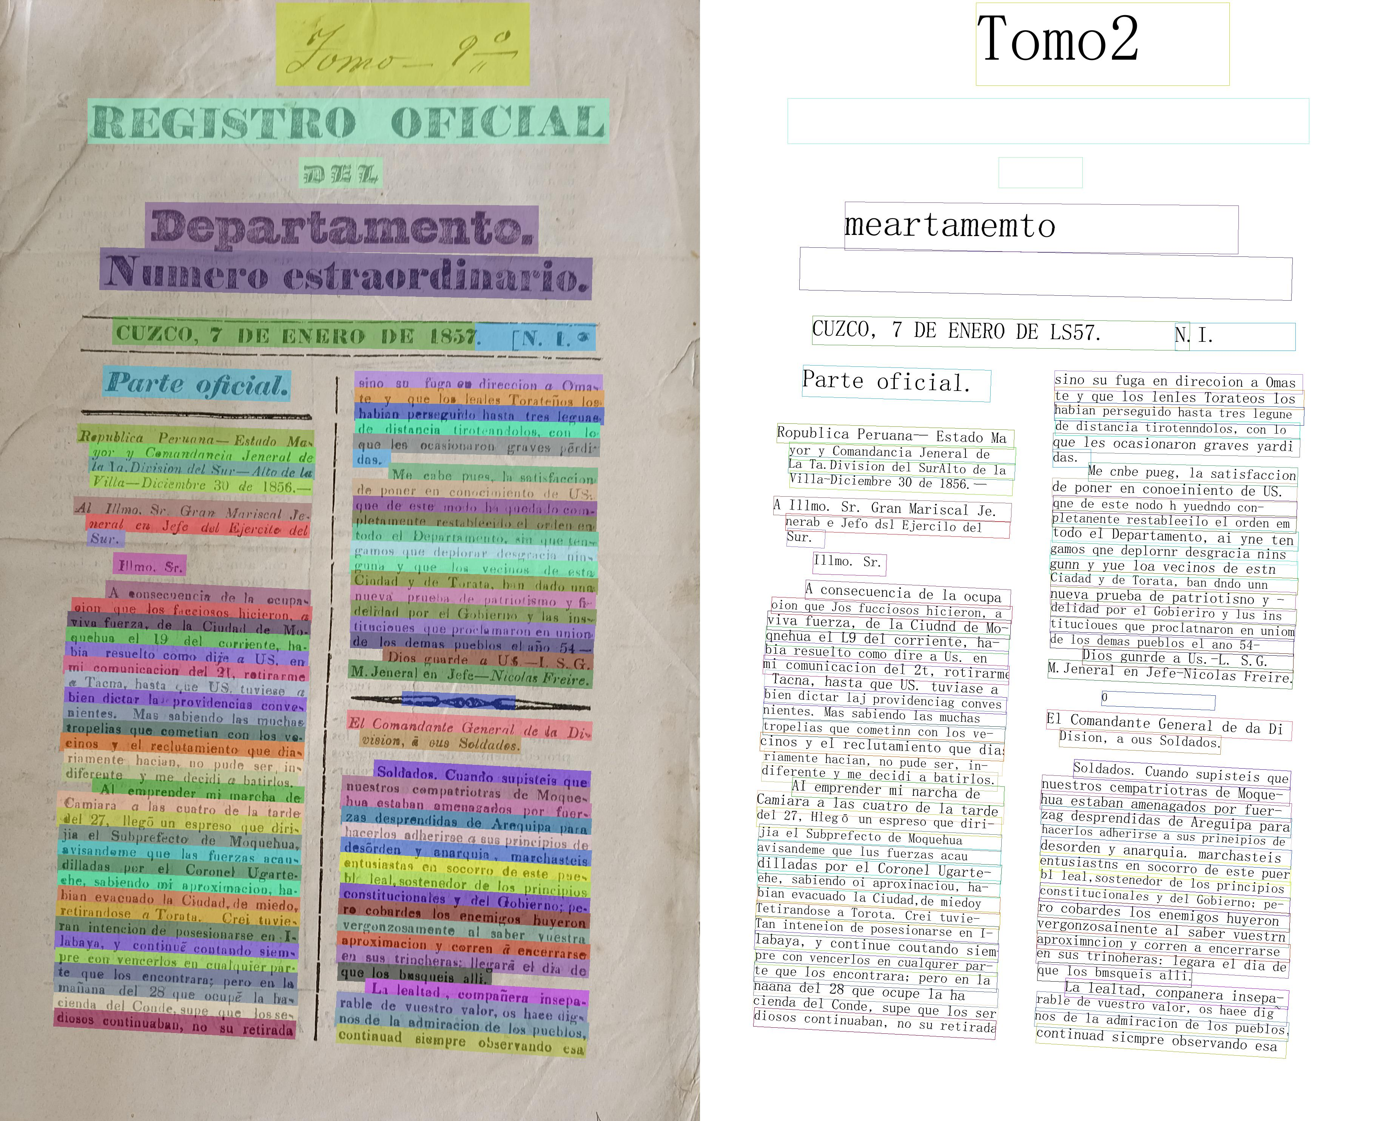

In [5]:
from PIL import Image
im = Image.open(DOCS / "ocr" / "paddle" / "doc_018_ocr_res_img.jpg")
im.thumbnail((1400, 1400))
im

## 4. ASR: transcripción y diarización

`asr_corpus.py` procesa cada clip con estos pasos:

1. **Transcripción:** faster-whisper large-v3-turbo (int8 en CPU), con el idioma fijado en español (`language="es"`) y `beam_size=5`.
2. **VAD (`vad_filter`):** se descartan los silencios y la música antes de transcribir, que es la causa típica de las alucinaciones de Whisper.
3. **Diarización:** se calcula la huella de voz WeSpeaker de cada segmento y se agrupan con clustering jerárquico por distancia coseno (umbral 0,7). Esto da el número de hablantes y la marca de cada segmento.
4. **Exportación:** CSV de segmentos, SRT de subtítulos y TXT por turnos en `datos/raw/audio/salidas/`.

In [6]:
r = subprocess.run([sys.executable, "asr_corpus.py"], capture_output=True, text=True)
print(r.stdout.strip().splitlines()[-1])
asr = pd.read_csv(AUDIO / "salidas" / "resumen_asr.csv")
clips = audio.merge(asr.drop(columns="duracion_seg"), on="id")
clips = clips[~clips["id"].isin(sin_voz["id"])].reset_index(drop=True)  # se transcribió, pero se descarta
print(f"Corpus de audio tras descartes: {len(clips)} clips, {clips['duracion_seg'].sum() / 60:.1f} min")
clips["rtf"] = (clips["segundos_asr"] / clips["duracion_seg"]).round(2)
salidas = sorted(p.suffix for p in (AUDIO / "salidas").glob("clip_*.*"))
print("Archivos exportados:", pd.Series(salidas).value_counts().to_dict())
display(clips[["id", "fuente", "condicion", "duracion_seg", "n_segmentos", "n_hablantes", "rtf"]])
print(f"Factor de tiempo real medio (tiempo de proceso / duración): {clips['segundos_asr'].sum() / clips['duracion_seg'].sum():.2f}")

listo: /Users/susanmontalvo/Documents/GitHub/Diplomado-Su-2026/tarea_2/datos/raw/audio/salidas/resumen_asr.csv
Corpus de audio tras descartes: 20 clips, 32.3 min
Archivos exportados: {'.csv': 21, '.srt': 21, '.txt': 21}


,id,fuente,condicion,duracion_seg,n_segmentos,n_hablantes,rtf
0,clip_001,Wikimedia Commons,calle,136.3,29,2,1.31
1,clip_002,Wikimedia Commons,"calle, 2+ hablantes",189.0,51,4,1.35
2,clip_003,Wikimedia Commons,conferencia,250.6,37,2,1.21
3,clip_005,Wikimedia Commons,"fiesta, ruido",81.6,16,2,1.49
4,clip_006,Wikimedia Commons,"marcha, ruido",77.4,16,2,1.20
5,clip_007,Wikimedia Commons,"marcha, ruido",95.0,38,5,4.18
6,clip_008,Wikimedia Commons,"marcha, ruido",54.3,11,3,1.18
7,clip_009,Wikimedia Commons,calle,196.0,43,2,1.66
8,clip_010,Wikimedia Commons,calle,96.1,8,1,1.69
9,clip_011,Wikimedia Commons,calle,77.4,13,2,1.41


Factor de tiempo real medio (tiempo de proceso / duración): 1.94


**Control de alucinaciones:** Whisper puede repetir una frase en bucle cuando le llega ruido. Para detectarlo se cuenta, en cada clip, la proporción de trigramas de palabras repetidos. Un valor alto indicaría un bucle de ese tipo.

In [7]:
def repeticion(texto):
    p = voz.normalizar(re.sub(r"\[H\d+\]", " ", texto)).split()
    tri = list(zip(p, p[1:], p[2:]))
    return round(1 - len(set(tri)) / len(tri), 3) if tri else 0.0

clips["repeticion_trigramas"] = clips["texto_asr"].map(repeticion)
display(clips.sort_values("repeticion_trigramas", ascending=False)[["id", "condicion", "repeticion_trigramas"]].head(5))

,id,condicion,repeticion_trigramas
11,clip_013,testimonio,0.062
1,clip_002,"calle, 2+ hablantes",0.060
12,clip_014,testimonio,0.059
8,clip_010,calle,0.052
5,clip_007,"marcha, ruido",0.052


## 5. Seudonimización

La regla que se aplica es:

- **Audio y manuscritos de SUNARP:** toda persona mencionada se reemplaza por un seudónimo (`PERSONA_01`, `PERSONA_02`…). Esto incluye entrevistados, entrevistadores, propietarios, notarios y registradores.
- **Impresos y fotos de periódicos:** son publicaciones públicas o históricas con figuras públicas (presidentes, ministros, autores del catálogo), así que no se seudonimizan.

El procedimiento tiene tres pasos:

1. **Detección automática:** el modelo NER en español marca las entidades de tipo persona (PER). Corre en un proceso aparte (`ner_personas.py`): en Mac Intel, si faster-whisper ya está cargado en el mismo proceso, torch falla en silencio ("Intel MKL ERROR … SGEMM") y el NER devuelve etiquetas sin sentido.
2. **Revisión humana:** la lista de candidatos se guarda en `datos/raw/seudonimizacion/reemplazos.csv`, que no se versiona porque contiene los nombres reales. Ahí se corrigen falsos positivos (por ejemplo "Dios" o el nombre de una calle) y se agregan los nombres que el NER no detectó.
3. **Reemplazo:** `voz.seudonimizar` usa comparación difusa, así que atrapa también nombres mal escritos por el OCR o el ASR. En los audios se reemplaza en cada segmento y se generan CSV, SRT y TXT seudonimizados en `datos/raw/audio/salidas/seudonimizado/`. Los originales no se modifican.

Este notebook se publica, así que nunca imprime nombres reales: solo conteos.

In [8]:
import tempfile

def personas_lote(textos):
    # {id: texto} -> {id: [nombres]}, con el NER corriendo en otro proceso (ver ner_personas.py)
    with tempfile.TemporaryDirectory() as d:
        entrada, salida = Path(d) / "in.json", Path(d) / "out.json"
        entrada.write_text(json.dumps(textos, ensure_ascii=False), encoding="utf-8")
        subprocess.run([sys.executable, "ner_personas.py", entrada, salida], check=True, capture_output=True)
        return json.loads(salida.read_text(encoding="utf-8"))

segmentos = {cid: pd.read_csv(AUDIO / "salidas" / f"{cid}.csv").fillna({"texto": ""}) for cid in clips["id"]}
privados = {f"{cid}": " ".join(t["texto"]) for cid, t in segmentos.items()}
privados |= dict(zip(docs.loc[docs["tipo"] == "manuscrito", "id"], docs.loc[docs["tipo"] == "manuscrito", "texto_ocr"].fillna("")))
candidatos = pd.DataFrame([(i, n) for i, ns in personas_lote(privados).items() for n in ns], columns=["id", "nombre"])

SEUD = RAW / "seudonimizacion"
SEUD.mkdir(exist_ok=True)
revisado = SEUD / "reemplazos.csv"
if not revisado.exists():  # primera vez: borrador a partir del NER, para revisar a mano
    nombres = sorted(candidatos["nombre"].unique(), key=str.lower)
    origen = ["ner"] * len(nombres)
    for ronda in (2, 3):  # el NER vuelve a leer el texto ya seudonimizado y suma lo que se le escapó
        borrador = {n: f"PERSONA_{i:02d}" for i, n in enumerate(nombres, 1)}
        nuevos = {n for ns in personas_lote({i: voz.seudonimizar(t, borrador) for i, t in privados.items()}).values()
                  for n in ns if "PERSONA" not in n} - set(nombres)
        if not nuevos:
            break
        nombres += sorted(nuevos, key=str.lower)
        origen += [f"ner, ronda {ronda}"] * len(nuevos)
    pd.DataFrame({"nombre": nombres, "seudonimo": [f"PERSONA_{i:02d}" for i in range(1, len(nombres) + 1)],
                  "aplicar": "si", "origen": origen}).to_csv(revisado, index=False)
reemplazos = pd.read_csv(revisado)
print(f"Entidades PER detectadas por el NER: {len(candidatos)} menciones, {candidatos['nombre'].nunique()} nombres distintos")
print("Revisión humana:", reemplazos.groupby(["origen", "aplicar"]).size().to_dict())

Entidades PER detectadas por el NER: 70 menciones, 60 nombres distintos
Revisión humana: {('ner', 'no'): 12, ('ner', 'si'): 48, ('ner, ronda 2', 'si'): 3}


In [9]:
mapa = dict(zip(reemplazos.loc[reemplazos["aplicar"] == "si", "nombre"], reemplazos.loc[reemplazos["aplicar"] == "si", "seudonimo"]))

def seudonimizar(texto):
    return voz.seudonimizar(texto, mapa) if isinstance(texto, str) and texto else texto

contar = lambda t: len(re.findall(r"PERSONA_\d+", t or ""))
# los originales quedan intactos en salidas/; las versiones publicables van a salidas/seudonimizado/
PUB = AUDIO / "salidas" / "seudonimizado"
PUB.mkdir(exist_ok=True)
for cid, t in segmentos.items():
    t["texto"] = t["texto"].map(seudonimizar)
    t.to_csv(PUB / f"{cid}.csv", index=False)
    seg = [voz.Segmento(r.inicio, r.fin, r.texto, r.hablante) for r in t.itertuples()]
    (PUB / f"{cid}.srt").write_text(voz.a_srt(seg), encoding="utf-8")
    (PUB / f"{cid}.txt").write_text(voz.a_texto(seg), encoding="utf-8")

# marcas de hablante como pide el enunciado: [HABLANTE_1] ...
clips["texto_asr"] = [" ".join(f"[HABLANTE_{h[1:]}] {x}" for h, x in zip(segmentos[c]["hablante"], segmentos[c]["texto"]))
                      for c in clips["id"]]
es_man = docs["tipo"] == "manuscrito"
docs.loc[es_man, "texto_ocr"] = docs.loc[es_man, "texto_ocr"].map(seudonimizar)

reemplazadas = pd.Series({"audio": clips["texto_asr"].map(contar).sum(), "manuscritos": docs.loc[es_man, "texto_ocr"].map(contar).sum()})
print("Entidades reemplazadas por seudónimos:", reemplazadas.to_dict(), "· total:", reemplazadas.sum())

# verificación: el NER ya no debería encontrar personas en los textos publicados
publicados = dict(zip(clips["id"], clips["texto_asr"])) | dict(zip(docs.loc[es_man, "id"], docs.loc[es_man, "texto_ocr"].fillna("")))
quedan = sum(len(v) for v in personas_lote(publicados).values())
print(f"Personas que el NER aún detecta tras seudonimizar: {quedan}")

Entidades reemplazadas por seudónimos: {'audio': 34, 'manuscritos': 59} · total: 93
Personas que el NER aún detecta tras seudonimizar: 9


Ejemplo de diarización en un audio con varios hablantes: clip_002, una entrevista en la calle a dos vendedoras en El Agustino. El texto ya está seudonimizado.

In [10]:
segmentos["clip_002"].head(12)

,inicio,fin,hablante,texto
0,0.02,8.02,H1,"Buenos días profesores y compañeros, hoy estoy cerca de aquí por mi casa y voy a hacer..."
1,8.72,10.02,H1,Estoy con las señoras...
2,10.62,12.82,H2,"PERSONA_31, soy PERSONA_60."
3,13.40,19.84,H1,"Muy bien, voy a comenzar con la primera pregunta y es, ¿qué expectativas tienen ante e..."
4,21.95,30.37,H3,Que el afición se encuentra motivado para ganar este partido.
5,30.37,31.91,H1,¿Me puede decir su nombre?
6,32.23,33.23,H3,PERSONA_31.
7,34.00,47.58,H2,"La expectativa que yo pienso es que acá, que el Perú va a dar todo por todo, todo su c..."
8,48.46,48.92,H1,Al mundial.
9,49.08,49.48,H4,Al mundial.


## 6. Análisis exploratorio

In [11]:
colores = {"impreso": "#4C78A8", "manuscrito": "#E45756", "foto": "#F58518"}
por_tipo = docs.groupby("tipo").agg(documentos=("id", "size"), confianza=("confianza_media", "mean")).reset_index()
por_tipo["etiqueta"] = por_tipo.apply(lambda r: f"{r.documentos} docs · confianza OCR {r.confianza:.2f}", axis=1)
conf = por_tipo.set_index("tipo")["confianza"]
fig = px.bar(por_tipo, x="tipo", y="documentos", color="tipo", color_discrete_map=colores, text="etiqueta",
             category_orders={"tipo": ["impreso", "foto", "manuscrito"]},
             title=f"Corpus equilibrado ({por_tipo.documentos.min()}-{por_tipo.documentos.max()} documentos por tipo), pero la confianza "
                   f"del OCR cae de {conf['impreso']:.2f} en impresos a {conf['manuscrito']:.2f} en manuscritos")
fig.update_layout(showlegend=False, yaxis_title="documentos", xaxis_title="tipo de documento")
fig.show()

In [12]:
minutos = clips.groupby("fuente")["duracion_seg"].sum() / 60
fig = px.bar(clips.sort_values("duracion_seg", ascending=False), x="id", y="duracion_seg", color="fuente",
             hover_data=["condicion", "n_hablantes"],
             title=f"Las entrevistas de Commons aportan el {minutos['Wikimedia Commons'] / minutos.sum():.0%} del audio "
                   f"({minutos['Wikimedia Commons']:.1f} de {minutos.sum():.1f} min); las frases de OpenSLR duran menos de "
                   f"{clips.loc[clips.fuente == 'OpenSLR 73', 'duracion_seg'].max():.0f} s")
fig.update_layout(xaxis_title="clip", yaxis_title="duración (s)")
fig.show()

In [13]:
longitudes = pd.concat([
    pd.DataFrame({"modalidad": "OCR (caracteres por documento)", "longitud": docs["caracteres_ocr"], "tipo": docs["tipo"]}),
    pd.DataFrame({"modalidad": "ASR (palabras por clip)", "longitud": clips["texto_asr"].str.replace(r"\[HABLANTE_\d+\]", "", regex=True).str.split().str.len(),
                  "tipo": clips["fuente"]}),
])
media = docs.groupby("tipo")["caracteres_ocr"].mean()
pal = longitudes[longitudes.modalidad.str.startswith("ASR")].groupby("tipo")["longitud"]
fig = px.histogram(longitudes, x="longitud", color="tipo", facet_col="modalidad", nbins=12,
                   color_discrete_map=colores | {"Wikimedia Commons": "#54A24B", "OpenSLR 73": "#B279A2"},
                   title=f"Las fotos de periódico dan {media['foto'] / media.drop('foto').mean():.1f} veces más texto OCR que impresos y manuscritos; "
                         f"en audio, las entrevistas ({pal.min()['Wikimedia Commons']}-{pal.max()['Wikimedia Commons']} palabras) "
                         f"se separan de las frases leídas (máx. {pal.max()['OpenSLR 73']})")
fig.update_xaxes(matches=None)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

## 7. Validación: casos extremos

Comparación con los histogramas: los 3 documentos con el texto OCR más largo y los 3 con el más corto, y lo mismo con los clips según su duración.

In [14]:
ver = lambda t: t.str.replace("\n", " ").str.slice(0, 160)
d = docs.assign(inicio_texto=ver(docs["texto_ocr"].fillna("")))[["id", "tipo", "caracteres_ocr", "confianza_media", "inicio_texto"]]
print("Documentos con OCR más largo"); display(d.nlargest(3, "caracteres_ocr"))
print("Documentos con OCR más corto"); display(d.nsmallest(3, "caracteres_ocr"))
c = clips.assign(palabras=clips["texto_asr"].str.replace(r"\[HABLANTE_\d+\]", "", regex=True).str.split().str.len(),
                 inicio_texto=ver(clips["texto_asr"]))[["id", "fuente", "duracion_seg", "palabras", "inicio_texto"]]
print("Clips más largos"); display(c.nlargest(3, "duracion_seg"))
print("Clips más cortos"); display(c.nsmallest(3, "duracion_seg"))

Documentos con OCR más largo


,id,tipo,caracteres_ocr,confianza_media,inicio_texto
22,doc_023,foto,8077,0.904,REGISTRO OFICIAL 8 EDe EDearlaet. TOMO X. CUZCO S.DE FEBRERO DE I8GI. NUM. 6. los in...
20,doc_021,foto,7926,0.906,"BEGISTRO OFICIAL DEI DEPARTAMENTO. taaimurio. 2 NUM.3 TOM.XI. CUZCO, ENERO 11 DE 1859..."
21,doc_022,foto,7699,0.841,BEGISTRO OFICIAL EBeL eeaet. NUM.T. CUzCO O DN ENERO DE 18OO. TOMO x1.? le hizo al den...


Documentos con OCR más corto


,id,tipo,caracteres_ocr,confianza_media,inicio_texto
2,doc_003,impreso,134,0.988,INDICE Periódicos cusqueños del siglo XIX Luis Miguel Glave Lista de Periódicos Catálo...
0,doc_001,impreso,362,0.978,CATALOGO DE PERIODICOS CUSQUENOS DEL SIGLO XIX UNIVERSIDAD NACIONAL DE SAN ANTONIO ABA...
19,doc_020,foto,504,0.645,2业 ATAEMATMAIEO ae WTO. 707008004 CNUMEKO *** 1 5 an 200 funciones en negocio determ...


Clips más largos


,id,fuente,duracion_seg,palabras,inicio_texto
2,clip_003,Wikimedia Commons,250.6,637,[HABLANTE_1] bueno ahora estamos en los san martín entre fiestas patrias de julio ento...
12,clip_014,Wikimedia Commons,212.9,690,[HABLANTE_1] Yo he ido a muchas salas de las que ya no existen y que ahora son otras c...
13,clip_015,Wikimedia Commons,207.8,559,"[HABLANTE_1] Ya no existe ese cine, el cine San Antonio. [HABLANTE_2] ¿Dónde quedaba? ..."


Clips más cortos


,id,fuente,duracion_seg,palabras,inicio_texto
16,clip_018,OpenSLR 73,4.4,8,[HABLANTE_1] La fiesta es para gente de la película
18,clip_020,OpenSLR 73,6.7,8,[HABLANTE_1] ¿Estás a cargo de la logística del evento?
19,clip_021,OpenSLR 73,6.7,18,[HABLANTE_1] El gobierno ha puesto a disposición de la población los medios necesarios...


**Lectura de los casos extremos** (coherente con los histogramas):

- **OCR más largo:** las 3 son fotos de páginas completas del *Registro Oficial* a 3 columnas, con unos 7700-8100 caracteres. Son la cola derecha del histograma de OCR. El cuerpo del texto sale bien (confianza 0,84-0,91), pero los títulos con tipografía decorativa se leen mal ("BEGISTRO OFICIAL", "EBeL eeaet."). Esos errores se medirán en la Parte 2.
- **OCR más corto:** doc_003 (índice) y doc_001 (portada) son páginas casi vacías, así que su texto corto es correcto y su confianza es 0,98: no son ilegibles. doc_020 es otro caso: es la foto del ejemplar deteriorado de 1858, con la tinta del reverso que se transparenta. Da solo 504 caracteres, confianza 0,65 y basura como caracteres chinos, porque el reconocedor PP-OCRv5 es multilingüe. No llega al umbral de descarte (texto < 20 caracteres o confianza < 0,5), así que se conserva como **caso difícil** para la Parte 2.
- **Clips más largos:** entrevistas y testimonios de Commons de 3,5 a 4 min, con 560-690 palabras (unas 160-195 palabras por minuto, habla espontánea).
- **Clips más cortos:** frases leídas de OpenSLR 73, de 4 a 7 s y 8 a 18 palabras. Explican el grupo separado a la izquierda del histograma de ASR.
- **Descartes:** 0 documentos ilegibles y 1 audio sin voz (clip_004, una fiesta con música: 10,6 s de voz en 98 s). Con eso, el corpus final queda en 25 documentos y 20 clips (32,3 min), por encima de los mínimos.

## 8. Exportación

Archivos que se generan:

- **`datos/documentos.csv`** y **`datos/transcripciones.csv`**: tienen las columnas que pide el enunciado. La columna `texto_referencia` queda vacía por ahora y se completa en la Parte 2 con las transcripciones manuales.
- **`datos/fuentes.csv`**: una fila por archivo con su fuente, licencia y forma de recuperarlo.

In [15]:
documentos = docs.assign(texto_referencia="")[["id", "archivo", "tipo", "fuente", "texto_ocr", "modelo_ocr", "texto_referencia"]]
documentos["fuente"] = docs["fuente"] + " — " + docs["licencia"]
transcripciones = clips.assign(idioma="es (español peruano, según la fuente)", texto_referencia="")[
    ["id", "archivo_audio", "duracion_seg", "idioma", "texto_asr", "modelo_asr", "n_hablantes", "texto_referencia"]]

acceso_doc = {"impreso": "Captura propia; no se redistribuye la imagen (derechos reservados). Publicación impresa del CBC (Cusco, 1999), ISBN 9972-691-23-3.",
              "manuscrito": "Captura propia; no se redistribuye (datos personales). Copia literal solicitable en SUNARP, Oficina Registral de Cusco.",
              "foto": "Foto propia; muestra publicada en datos/ejemplos/documentos/ (dominio público)."}
fuentes = pd.concat([
    pd.DataFrame({"id": docs["id"], "modalidad": "documento", "tipo": docs["tipo"], "fuente_url": "", "autor": "Captura propia",
                  "licencia": docs["licencia"], "acceso": docs["tipo"].map(acceso_doc)}),
    pd.DataFrame({"id": clips["id"], "modalidad": "audio", "tipo": clips["condicion"], "fuente_url": clips["fuente_url"],
                  "autor": clips["autor"], "licencia": clips["licencia"], "acceso": clips["acceso"]}),
], ignore_index=True)

(AQUI / "datos").mkdir(exist_ok=True)
documentos.to_csv(AQUI / "datos" / "documentos.csv", index=False)
transcripciones.to_csv(AQUI / "datos" / "transcripciones.csv", index=False)
fuentes.to_csv(AQUI / "datos" / "fuentes.csv", index=False)
for nombre, t in [("documentos", documentos), ("transcripciones", transcripciones), ("fuentes", fuentes)]:
    print(f"datos/{nombre}.csv: {t.shape}")
display(documentos.head())
display(transcripciones.head())

datos/documentos.csv: (25, 7)
datos/transcripciones.csv: (20, 8)
datos/fuentes.csv: (45, 7)


,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia
0,doc_001,datos/raw/documentos/doc_001.png,impreso,"Captura propia del PDF de Glave, L. M. (1999). Catálogo de periódicos cusqueños del si...",CATALOGO DE PERIODICOS\nCUSQUENOS\nDEL SIGLO XIX\nUNIVERSIDAD NACIONAL DE SAN ANTONIO ...,"PaddleOCR 3.0.3 (PP-OCRv5_mobile_det + PP-OCRv5_mobile_rec, det 1600 px, CPU, sin orie...",
1,doc_002,datos/raw/documentos/doc_002.png,impreso,"Captura propia del PDF de Glave, L. M. (1999). Catálogo de periódicos cusqueños del si...","ARCHIVOS DE HISTORIA ANDINA\n34\nCBC-SID\nGlave Testino, Luis Miguel\nCatálogo de peri...","PaddleOCR 3.0.3 (PP-OCRv5_mobile_det + PP-OCRv5_mobile_rec, det 1600 px, CPU, sin orie...",
2,doc_003,datos/raw/documentos/doc_003.png,impreso,"Captura propia del PDF de Glave, L. M. (1999). Catálogo de periódicos cusqueños del si...",INDICE\nPeriódicos cusqueños del siglo XIX\nLuis Miguel Glave\nLista de Periódicos\nCa...,"PaddleOCR 3.0.3 (PP-OCRv5_mobile_det + PP-OCRv5_mobile_rec, det 1600 px, CPU, sin orie...",
3,doc_004,datos/raw/documentos/doc_004.png,impreso,"Captura propia del PDF de Glave, L. M. (1999). Catálogo de periódicos cusqueños del si...",PRESENTACION\nEn la Hemeroteca de la Biblioteca Central de la Universidad Nacional San...,"PaddleOCR 3.0.3 (PP-OCRv5_mobile_det + PP-OCRv5_mobile_rec, det 1600 px, CPU, sin orie...",
4,doc_005,datos/raw/documentos/doc_005.png,impreso,"Captura propia del PDF de Glave, L. M. (1999). Catálogo de periódicos cusqueños del si...",PRESENTACION\nEn el siglo XIX hubo en la ciudad del Cusco una importantísima producció...,"PaddleOCR 3.0.3 (PP-OCRv5_mobile_det + PP-OCRv5_mobile_rec, det 1600 px, CPU, sin orie...",


,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia
0,clip_001,datos/raw/audio/clip_001.wav,136.3,"es (español peruano, según la fuente)","[HABLANTE_1] Buenos días, aquí son las 10 y 28 y estoy con una señora que va a darme s...","faster-whisper large-v3-turbo (int8, CPU, language=es, VAD on, beam=5) + diarización W...",2,
1,clip_002,datos/raw/audio/clip_002.wav,189.0,"es (español peruano, según la fuente)","[HABLANTE_1] Buenos días profesores y compañeros, hoy estoy cerca de aquí por mi casa ...","faster-whisper large-v3-turbo (int8, CPU, language=es, VAD on, beam=5) + diarización W...",4,
2,clip_003,datos/raw/audio/clip_003.wav,250.6,"es (español peruano, según la fuente)",[HABLANTE_1] bueno ahora estamos en los san martín entre fiestas patrias de julio ento...,"faster-whisper large-v3-turbo (int8, CPU, language=es, VAD on, beam=5) + diarización W...",2,
3,clip_005,datos/raw/audio/clip_005.wav,81.6,"es (español peruano, según la fuente)","[HABLANTE_1] ¿Cuál es su nombre? PERSONA_18. Ah, ok. Usted, este, me acaba de decir qu...","faster-whisper large-v3-turbo (int8, CPU, language=es, VAD on, beam=5) + diarización W...",2,
4,clip_006,datos/raw/audio/clip_006.wav,77.4,"es (español peruano, según la fuente)","[HABLANTE_1] Sí, yo soy PERSONA_14 de la Facultad de Ciencias Biológicas [HABLANTE_1] ...","faster-whisper large-v3-turbo (int8, CPU, language=es, VAD on, beam=5) + diarización W...",2,
